In [ ]:
# ============================================================
# AUTOSOC - UPDATED FINAL VERSION
# CELL 1
# DATA QUALITY + PREPROCESSING + ML THREAT DETECTION
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import gc
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from IPython.display import display, HTML

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# PROJECT PATH
# ------------------------------------------------------------

BASE_PATH = "/content/drive/MyDrive/AutoSOC_Project"

TRAIN_FILE = os.path.join(
    BASE_PATH,
    "train_test_network.csv"
)

# ------------------------------------------------------------
# NUMERICAL FEATURES
# ------------------------------------------------------------

FEATURES = [
    "src_port",
    "dst_port",
    "duration",
    "src_bytes",
    "dst_bytes",
    "missed_bytes",
    "src_pkts",
    "src_ip_bytes",
    "dst_pkts",
    "dst_ip_bytes",
    "dns_qclass",
    "dns_qtype",
    "dns_rcode",
    "http_request_body_len",
    "http_response_body_len",
    "http_status_code"
]

print("=" * 90)
print("CELL 1 - DATA QUALITY + PREPROCESSING + RANDOM FOREST")
print("=" * 90)

# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(
    TRAIN_FILE,
    low_memory=False
)

print("\nOriginal dataset shape:")
print(df.shape)

# ------------------------------------------------------------
# REMOVE DUPLICATES
# ------------------------------------------------------------

before = len(df)

df = (
    df
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    "\nExact duplicate rows removed:",
    before - len(df)
)

print(
    "Dataset after duplicate removal:",
    df.shape
)

# ------------------------------------------------------------
# CLEAN TARGET LABEL
# ------------------------------------------------------------

df["type"] = (
    df["type"]
    .astype(str)
    .str.lower()
    .str.strip()
)

print("\nAttack class distribution:")

display(
    df["type"]
    .value_counts()
    .rename_axis("Attack")
    .reset_index(name="Samples")
)

# ------------------------------------------------------------
# PREPARE FEATURES
# ------------------------------------------------------------

X = df[FEATURES].copy()

for col in FEATURES:

    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )

X = (
    X
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .fillna(0)
)

y = df["type"].copy()

# ------------------------------------------------------------
# TRAIN / TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(
    "\nTraining samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

# ------------------------------------------------------------
# RANDOM FOREST
# ------------------------------------------------------------

threat_model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

threat_model.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# HELD-OUT PREDICTION
# ------------------------------------------------------------

y_pred = threat_model.predict(
    X_test
)

test_accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "\nHeld-out test accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

# ------------------------------------------------------------
# FEATURE IMPORTANCE
# ------------------------------------------------------------

feature_importance = (
    pd.DataFrame({

        "Feature":
            FEATURES,

        "Importance":
            threat_model.feature_importances_
    })

    .sort_values(
        "Importance",
        ascending=False
    )

    .reset_index(drop=True)
)

print(
    "\nTop Random Forest features:"
)

display(
    feature_importance.head(10)
)

print("\nCELL 1 COMPLETE ✅")

Mounted at /content/drive
CELL 1 - DATA QUALITY + PREPROCESSING + RANDOM FOREST

Original dataset shape:
(211043, 44)

Exact duplicate rows removed: 20569
Dataset after duplicate removal: (190474, 44)

Attack class distribution:


,Attack,Samples
0,normal,42040
1,scanning,20000
2,ddos,19993
3,injection,19964
4,password,19861
5,dos,18992
6,backdoor,18711
7,xss,15137
8,ransomware,14735
9,mitm,1041



Training samples: 152379
Testing samples: 38095

Held-out test accuracy: 98.74%

Classification Report:

              precision    recall  f1-score   support

    backdoor       1.00      1.00      1.00      3742
        ddos       0.99      0.98      0.98      3999
         dos       0.99      0.98      0.99      3799
   injection       0.98      0.97      0.97      3993
        mitm       0.76      0.83      0.79       208
      normal       1.00      1.00      1.00      8408
    password       1.00      0.99      0.99      3972
  ransomware       1.00      1.00      1.00      2947
    scanning       0.99      0.99      0.99      4000
         xss       0.96      0.97      0.96      3027

    accuracy                           0.99     38095
   macro avg       0.96      0.97      0.97     38095
weighted avg       0.99      0.99      0.99     38095


Top Random Forest features:


,Feature,Importance
0,src_ip_bytes,0.223964
1,dst_port,0.133379
2,src_port,0.110243
3,duration,0.107138
4,dst_ip_bytes,0.101257
5,src_bytes,0.081012
6,src_pkts,0.073086
7,dst_pkts,0.063018
8,dst_bytes,0.060782
9,dns_qclass,0.020006



CELL 1 COMPLETE ✅


In [ ]:
# ============================================================
# AUTOSOC - UPDATED FINAL VERSION
# CELL 2
# EXTERNAL PREDICTION + CONFIDENCE-AWARE ALERT FILTERING
# ============================================================

NETWORK_FILES = [
    1,
    9,
    16,
    18
]

# Current operational baseline
OPERATIONAL_THRESHOLD = 0.80

# Sensitivity comparison
THRESHOLDS_TO_COMPARE = [
    0.70,
    0.80,
    0.90
]

LABELS = list(
    threat_model.classes_
)

cm_total = np.zeros(
    (
        len(LABELS),
        len(LABELS)
    ),
    dtype=np.int64
)

threshold_stats = {

    threshold: {
        "total": 0,
        "correct": 0
    }

    for threshold
    in THRESHOLDS_TO_COMPARE
}

total_external_events = 0
total_external_correct = 0

event_parts = []

print("=" * 90)
print("CELL 2 - EXTERNAL DETECTION + CONFIDENCE FILTERING")
print("=" * 90)

# ------------------------------------------------------------
# PROCESS TIMESTAMPED NETWORK FILES
# ------------------------------------------------------------

for file_id in NETWORK_FILES:

    path = os.path.join(
        BASE_PATH,
        f"Network_dataset_{file_id}.csv"
    )

    print(
        f"\nProcessing Network_dataset_{file_id}.csv"
    )

    available_columns = pd.read_csv(
        path,
        nrows=0
    ).columns.tolist()

    required_columns = [

        "ts",
        "src_ip",
        "dst_ip",
        "type"

    ] + FEATURES

    missing_columns = [

        col

        for col
        in required_columns

        if col
        not in available_columns
    ]

    if missing_columns:

        raise ValueError(

            f"Network_dataset_{file_id}.csv "
            f"is missing columns: "
            f"{missing_columns}"
        )

    file_forwarded = 0

    chunks = pd.read_csv(

        path,

        usecols=required_columns,

        chunksize=200000,

        low_memory=False
    )

    for chunk in chunks:

        chunk = chunk.reset_index(
            drop=True
        )

        # ----------------------------------------------------
        # NUMERIC PREPROCESSING
        # ----------------------------------------------------

        for col in FEATURES:

            chunk[col] = pd.to_numeric(
                chunk[col],
                errors="coerce"
            )

        chunk[FEATURES] = (

            chunk[FEATURES]

            .replace(
                [np.inf, -np.inf],
                np.nan
            )

            .fillna(0)
        )

        # ----------------------------------------------------
        # PREDICTION
        # ----------------------------------------------------

        predictions = threat_model.predict(
            chunk[FEATURES]
        )

        probabilities = threat_model.predict_proba(
            chunk[FEATURES]
        )

        confidence = probabilities.max(
            axis=1
        )

        predictions = (

            pd.Series(predictions)

            .astype(str)

            .str.lower()

            .str.strip()

            .to_numpy()
        )

        # ----------------------------------------------------
        # ACTUAL LABEL
        # ONLY FOR EVALUATION
        # ----------------------------------------------------

        actual = (

            chunk["type"]

            .astype(str)

            .str.lower()

            .str.strip()

            .to_numpy()
        )

        valid_eval = np.isin(
            actual,
            LABELS
        )

        actual_eval = actual[
            valid_eval
        ]

        pred_eval = predictions[
            valid_eval
        ]

        conf_eval = confidence[
            valid_eval
        ]

        # ----------------------------------------------------
        # EXTERNAL CONFUSION MATRIX
        # ----------------------------------------------------

        cm_total += confusion_matrix(

            actual_eval,

            pred_eval,

            labels=LABELS
        )

        total_external_events += len(
            actual_eval
        )

        total_external_correct += int(

            (
                actual_eval
                ==
                pred_eval
            ).sum()
        )

        # ----------------------------------------------------
        # THRESHOLD SENSITIVITY
        # ----------------------------------------------------

        for threshold in THRESHOLDS_TO_COMPARE:

            mask_threshold = (

                conf_eval
                >=
                threshold
            )

            threshold_stats[
                threshold
            ]["total"] += int(

                mask_threshold.sum()
            )

            threshold_stats[
                threshold
            ]["correct"] += int(

                (
                    actual_eval[
                        mask_threshold
                    ]
                    ==
                    pred_eval[
                        mask_threshold
                    ]
                ).sum()
            )

        # ----------------------------------------------------
        # AUTONOMOUS FORWARDING
        #
        # IMPORTANT:
        # Ground truth is NOT used here.
        # ----------------------------------------------------

        autonomous_mask = (

            (
                predictions
                !=
                "normal"
            )

            &

            (
                confidence
                >=
                OPERATIONAL_THRESHOLD
            )
        )

        temp = pd.DataFrame({

            "ts":

                pd.to_numeric(

                    chunk.loc[
                        autonomous_mask,
                        "ts"
                    ],

                    errors="coerce"

                ).to_numpy(),

            "src_ip":

                chunk.loc[
                    autonomous_mask,
                    "src_ip"
                ]

                .astype(str)

                .str.strip()

                .to_numpy(),

            "dst_ip":

                chunk.loc[
                    autonomous_mask,
                    "dst_ip"
                ]

                .astype(str)

                .str.strip()

                .to_numpy(),

            "predicted_type":

                predictions[
                    autonomous_mask
                ],

            "confidence":

                confidence[
                    autonomous_mask
                ],

            "source_file":

                file_id
        })

        temp = temp.replace({

            "src_ip": {
                "nan": np.nan,
                "": np.nan
            },

            "dst_ip": {
                "nan": np.nan,
                "": np.nan
            }
        })

        temp = temp.dropna(

            subset=[
                "ts",
                "src_ip",
                "dst_ip",
                "predicted_type",
                "confidence"
            ]
        )

        event_parts.append(
            temp
        )

        file_forwarded += len(
            temp
        )

        del chunk
        del temp
        del predictions
        del probabilities
        del confidence

        gc.collect()

    print(
        "Forwarded malicious events:",
        file_forwarded
    )

# ------------------------------------------------------------
# COMBINE FORWARDED EVENTS
# ------------------------------------------------------------

detected_events = pd.concat(
    event_parts,
    ignore_index=True
)

del event_parts
gc.collect()

# ------------------------------------------------------------
# EXTERNAL AGREEMENT
# ------------------------------------------------------------

external_accuracy = (

    total_external_correct
    /
    total_external_events

    if total_external_events

    else 0
)

# ------------------------------------------------------------
# THRESHOLD SUMMARY
# ------------------------------------------------------------

threshold_rows = []

for threshold in THRESHOLDS_TO_COMPARE:

    total = threshold_stats[
        threshold
    ]["total"]

    correct = threshold_stats[
        threshold
    ]["correct"]

    threshold_rows.append({

        "Threshold":
            threshold,

        "Agreement":

            correct / total

            if total

            else 0,

        "Coverage":

            total / total_external_events

            if total_external_events

            else 0
    })

threshold_summary = pd.DataFrame(
    threshold_rows
)

threshold_summary[
    "Agreement"
] = (

    threshold_summary[
        "Agreement"
    ]
    *
    100

).round(2)

threshold_summary[
    "Coverage"
] = (

    threshold_summary[
        "Coverage"
    ]
    *
    100

).round(2)

row_080 = threshold_summary[

    threshold_summary[
        "Threshold"
    ]
    ==
    OPERATIONAL_THRESHOLD

].iloc[0]

high_conf_accuracy = (
    row_080[
        "Agreement"
    ]
    /
    100
)

high_conf_coverage = (
    row_080[
        "Coverage"
    ]
    /
    100
)

print(
    "\nOverall external agreement:",
    f"{external_accuracy * 100:.2f}%"
)

print(
    "\nConfidence Threshold Comparison:"
)

display(
    threshold_summary
)

print(
    "\nHigh-confidence malicious events "
    "sent to correlation:",
    f"{len(detected_events):,}"
)

print(
    "\nForwarded attack distribution:"
)

display(

    detected_events[
        "predicted_type"
    ]

    .value_counts()

    .rename_axis(
        "Attack"
    )

    .reset_index(
        name="Events"
    )
)

# ------------------------------------------------------------
# EXTERNAL CLASS-WISE METRICS
# ------------------------------------------------------------

true_positive = np.diag(
    cm_total
).astype(float)

support = cm_total.sum(
    axis=1
).astype(float)

predicted_count = cm_total.sum(
    axis=0
).astype(float)

external_precision = np.divide(

    true_positive,

    predicted_count,

    out=np.zeros_like(
        true_positive
    ),

    where=predicted_count != 0
)

external_recall = np.divide(

    true_positive,

    support,

    out=np.zeros_like(
        true_positive
    ),

    where=support != 0
)

external_f1 = np.divide(

    2
    *
    external_precision
    *
    external_recall,

    external_precision
    +
    external_recall,

    out=np.zeros_like(
        true_positive
    ),

    where=(
        external_precision
        +
        external_recall
    )
    !=
    0
)

external_report = pd.DataFrame({

    "Class":
        LABELS,

    "Precision":
        external_precision.round(3),

    "Recall":
        external_recall.round(3),

    "F1":
        external_f1.round(3),

    "Support":
        support.astype(int)
})

print(
    "\nExternal Class-wise Evaluation:"
)

display(
    external_report
)

print(
    "\nIMPORTANT:"
)

print(
    "Ground-truth labels were used only "
    "for model evaluation."
)

print(
    "Ground truth was NOT used to select "
    "events for attack correlation."
)

print("\nCELL 2 COMPLETE ✅")

CELL 2 - EXTERNAL DETECTION + CONFIDENCE FILTERING

Processing Network_dataset_1.csv
Forwarded malicious events: 135907

Processing Network_dataset_9.csv
Forwarded malicious events: 22740

Processing Network_dataset_16.csv
Forwarded malicious events: 602444

Processing Network_dataset_18.csv
Forwarded malicious events: 492084

Overall external agreement: 56.30%

Confidence Threshold Comparison:


,Threshold,Agreement,Coverage
0,0.7,89.88,45.54
1,0.8,93.07,41.57
2,0.9,95.08,37.47



High-confidence malicious events sent to correlation: 1,253,175

Forwarded attack distribution:


,Attack,Events
0,ddos,862186
1,password,167131
2,scanning,123998
3,xss,72585
4,dos,22556
5,ransomware,2271
6,backdoor,1573
7,injection,735
8,mitm,140



External Class-wise Evaluation:


,Class,Precision,Recall,F1,Support
0,backdoor,0.000,0.000,0.000,0
1,ddos,0.986,0.793,0.879,1425202
2,dos,0.152,0.023,0.040,975261
3,injection,0.000,0.000,0.000,0
4,mitm,0.000,0.000,0.000,0
5,normal,0.394,0.954,0.558,281093
6,password,0.869,0.814,0.841,206891
7,ransomware,0.000,0.000,0.000,0
8,scanning,0.461,0.611,0.525,791321
9,xss,0.000,0.000,0.000,0



IMPORTANT:
Ground-truth labels were used only for model evaluation.
Ground truth was NOT used to select events for attack correlation.

CELL 2 COMPLETE ✅


In [ ]:
# ============================================================
# AUTOSOC - UPDATED FINAL VERSION
# CELL 3
# ROBUST ENTITY + TEMPORAL ATTACK CORRELATION
# + NOISE-RESISTANT MULTI-STAGE CAMPAIGN INFERENCE
# ============================================================

print("=" * 95)
print("CELL 3 - ROBUST ATTACK CORRELATION + TEMPORAL REASONING")
print("=" * 95)


# ============================================================
# 1. ANALYTICAL ATTACK-STAGE MAPPING
#
# These stages are used for analytical correlation.
# They DO NOT prove a confirmed causal attack chain.
# ============================================================

ATTACK_STAGE_MAP = {

    "scanning":
        "Reconnaissance/Discovery",

    "xss":
        "Initial Access",

    "injection":
        "Initial Access",

    "password":
        "Credential Access",

    "mitm":
        "Credential Access",

    "backdoor":
        "Persistence",

    "ransomware":
        "Impact",

    "dos":
        "Impact",

    "ddos":
        "Impact"
}


# ------------------------------------------------------------
# STAGE ORDER
# ------------------------------------------------------------

STAGE_ORDER = {

    "Reconnaissance/Discovery": 1,

    "Initial Access": 2,

    "Credential Access": 3,

    "Persistence": 4,

    "Impact": 5
}


# ============================================================
# 2. CORRELATION PARAMETERS
# ============================================================

# 30 minutes inactivity separates two campaigns
CAMPAIGN_WINDOW = 1800


# A predicted label must have enough events
# before it is allowed to become a meaningful campaign stage.
MIN_STAGE_EVENTS = 10


# Minimum 0.5% of campaign events must support the label.
# This helps remove tiny classifier-noise classes.
MIN_STAGE_SHARE = 0.005


# At least 75% of adjacent stage transitions
# should move forward.
MIN_PROGRESSION_RATIO = 0.75


# At least 50% of adjacent attack types should
# share one or more destination targets.
MIN_TARGET_RELATIONSHIP_RATIO = 0.50


# ============================================================
# 3. PREPARE DETECTED MALICIOUS EVENTS
# ============================================================

events = detected_events[
    [
        "ts",
        "src_ip",
        "dst_ip",
        "predicted_type",
        "confidence"
    ]
].copy()


events = events.rename(
    columns={
        "predicted_type":
            "attack_type"
    }
)


# ------------------------------------------------------------
# CLEAN NUMERIC COLUMNS
# ------------------------------------------------------------

events["ts"] = pd.to_numeric(
    events["ts"],
    errors="coerce"
)

events["confidence"] = pd.to_numeric(
    events["confidence"],
    errors="coerce"
)


# ------------------------------------------------------------
# CLEAN TEXT
# ------------------------------------------------------------

events["src_ip"] = (
    events["src_ip"]
    .astype(str)
    .str.strip()
)

events["dst_ip"] = (
    events["dst_ip"]
    .astype(str)
    .str.strip()
)

events["attack_type"] = (
    events["attack_type"]
    .astype(str)
    .str.lower()
    .str.strip()
)


events = events.dropna(
    subset=[
        "ts",
        "src_ip",
        "dst_ip",
        "attack_type",
        "confidence"
    ]
)


# Remove invalid text values
invalid_values = {
    "",
    "nan",
    "none",
    "-"
}

events = events[
    ~events[
        "src_ip"
    ]
    .str.lower()
    .isin(
        invalid_values
    )
].copy()

events = events[
    ~events[
        "dst_ip"
    ]
    .str.lower()
    .isin(
        invalid_values
    )
].copy()


# ============================================================
# 4. MAP ATTACK TYPE TO ANALYTICAL STAGE
# ============================================================

events[
    "attack_stage"
] = (
    events[
        "attack_type"
    ]
    .map(
        ATTACK_STAGE_MAP
    )
)


events = (
    events
    .dropna(
        subset=[
            "attack_stage"
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nHigh-confidence malicious events entering correlation:",
    f"{len(events):,}"
)


# ============================================================
# 5. ACTOR-CENTRIC TEMPORAL SESSIONIZATION
#
# Same source IP = same candidate actor.
# Multiple destination IPs are allowed.
#
# This improves over strict src_ip + dst_ip grouping.
# ============================================================

events = (
    events
    .sort_values(
        [
            "src_ip",
            "ts"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# TIME GAP FROM PREVIOUS EVENT OF SAME SOURCE
# ------------------------------------------------------------

events[
    "time_gap"
] = (
    events
    .groupby(
        "src_ip"
    )[
        "ts"
    ]
    .diff()
)


# ------------------------------------------------------------
# NEW CAMPAIGN AFTER 30 MINUTES OF INACTIVITY
# ------------------------------------------------------------

events[
    "new_campaign"
] = (
    events[
        "time_gap"
    ].isna()

    |

    (
        events[
            "time_gap"
        ]
        >
        CAMPAIGN_WINDOW
    )
)


events[
    "campaign_id"
] = (
    events
    .groupby(
        "src_ip"
    )[
        "new_campaign"
    ]
    .cumsum()
)


# ============================================================
# 6. HELPER FUNCTIONS
# ============================================================

def collapse_consecutive(items):

    result = []

    previous = None

    for item in items:

        if pd.isna(item):
            continue

        item = str(
            item
        ).strip()

        if item != previous:

            result.append(
                item
            )

        previous = item

    return result


# ------------------------------------------------------------
# LONGEST INCREASING STAGE SUBSEQUENCE
# ------------------------------------------------------------

def longest_increasing_subsequence_length(values):

    if len(values) == 0:
        return 0

    dp = [
        1
    ] * len(values)

    for i in range(
        len(values)
    ):

        for j in range(i):

            if (
                values[j]
                <
                values[i]
            ):

                dp[i] = max(
                    dp[i],
                    dp[j] + 1
                )

    return max(dp)


# ------------------------------------------------------------
# TARGET RELATIONSHIP BETWEEN TWO ATTACK TYPES
# ------------------------------------------------------------

def has_target_overlap(
    group,
    attack_a,
    attack_b
):

    targets_a = set(
        group.loc[
            group[
                "attack_type"
            ]
            ==
            attack_a,
            "dst_ip"
        ]
        .astype(str)
        .tolist()
    )

    targets_b = set(
        group.loc[
            group[
                "attack_type"
            ]
            ==
            attack_b,
            "dst_ip"
        ]
        .astype(str)
        .tolist()
    )

    return (
        len(
            targets_a
            &
            targets_b
        )
        >
        0
    )


# ============================================================
# 7. CAMPAIGN SUMMARIZATION
# ============================================================

def summarize_campaign(group):

    group = (
        group
        .sort_values(
            "ts"
        )
        .copy()
    )

    total_events = len(
        group
    )


    # ========================================================
    # A. DYNAMIC LABEL-SUPPORT THRESHOLD
    # ========================================================

    support_threshold = max(

        MIN_STAGE_EVENTS,

        int(
            math.ceil(
                total_events
                *
                MIN_STAGE_SHARE
            )
        )
    )


    attack_counts = (
        group[
            "attack_type"
        ]
        .value_counts()
    )


    # --------------------------------------------------------
    # ONLY LABELS WITH MEANINGFUL SUPPORT
    # --------------------------------------------------------

    supported_attacks = (
        attack_counts[
            attack_counts
            >=
            support_threshold
        ]
        .index
        .tolist()
    )


    # ========================================================
    # B. FIRST-SEEN ORDER OF SUPPORTED ATTACK LABELS
    # ========================================================

    if len(
        supported_attacks
    ) > 0:

        first_seen = (
            group[
                group[
                    "attack_type"
                ]
                .isin(
                    supported_attacks
                )
            ]
            .groupby(
                "attack_type"
            )[
                "ts"
            ]
            .min()
            .sort_values()
        )

        ordered_attacks = (
            first_seen
            .index
            .tolist()
        )

    else:

        ordered_attacks = []


    # ========================================================
    # C. STAGE SEQUENCE
    # ========================================================

    raw_stages = [

        ATTACK_STAGE_MAP.get(
            attack
        )

        for attack
        in ordered_attacks
    ]


    ordered_stages = (
        collapse_consecutive(
            raw_stages
        )
    )


    stage_ranks = [

        STAGE_ORDER[
            stage
        ]

        for stage
        in ordered_stages

        if stage
        in STAGE_ORDER
    ]


    # ========================================================
    # D. FORWARD-PROGRESSION RATIO
    # ========================================================

    if len(
        stage_ranks
    ) >= 2:

        forward_transitions = sum(

            1

            for previous_stage,
                next_stage

            in zip(
                stage_ranks[:-1],
                stage_ranks[1:]
            )

            if (
                next_stage
                >
                previous_stage
            )
        )


        total_transitions = (
            len(
                stage_ranks
            )
            -
            1
        )


        progression_ratio = (

            forward_transitions
            /
            total_transitions

            if total_transitions > 0

            else 0
        )


        lis_length = (
            longest_increasing_subsequence_length(
                stage_ranks
            )
        )

    else:

        progression_ratio = 0.0

        lis_length = len(
            stage_ranks
        )


    # ========================================================
    # E. FIRST-TO-LAST PROGRESSION CHECK
    #
    # Campaign should ultimately move toward a later stage.
    # ========================================================

    if len(
        stage_ranks
    ) >= 2:

        first_to_last_forward = (
            stage_ranks[-1]
            >
            stage_ranks[0]
        )

    else:

        first_to_last_forward = False


    # ========================================================
    # F. TARGET-RELATIONSHIP EVIDENCE
    #
    # Adjacent attack types should share target evidence.
    # Example:
    # scanning hits Host-B and later password attack also
    # targets Host-B.
    # ========================================================

    if len(
        ordered_attacks
    ) >= 2:

        related_pairs = 0

        total_pairs = (
            len(
                ordered_attacks
            )
            -
            1
        )

        for attack_a, attack_b in zip(
            ordered_attacks[:-1],
            ordered_attacks[1:]
        ):

            if has_target_overlap(
                group,
                attack_a,
                attack_b
            ):

                related_pairs += 1


        target_relationship_ratio = (

            related_pairs
            /
            total_pairs

            if total_pairs > 0

            else 0
        )

    else:

        target_relationship_ratio = 0.0


    # ========================================================
    # G. SUPPORTED EVENT SHARE
    # ========================================================

    supported_event_count = sum(

        int(
            attack_counts[
                attack
            ]
        )

        for attack
        in supported_attacks
    )


    supported_event_share = (

        supported_event_count
        /
        total_events

        if total_events > 0

        else 0
    )


    # ========================================================
    # H. FINAL CANDIDATE MULTI-STAGE DECISION
    #
    # Must satisfy ALL major evidence conditions.
    # ========================================================

    candidate_multistage = (

        # At least 2 meaningful attack labels
        len(
            ordered_attacks
        )
        >=
        2

        and

        # At least 2 distinct analytical stages
        len(
            set(
                ordered_stages
            )
        )
        >=
        2

        and

        # Must contain forward progression evidence
        lis_length
        >=
        2

        and

        # At least 75% adjacent stage transitions forward
        progression_ratio
        >=
        MIN_PROGRESSION_RATIO

        and

        # First meaningful stage must end at later stage
        first_to_last_forward

        and

        # Related attacks should share target evidence
        target_relationship_ratio
        >=
        MIN_TARGET_RELATIONSHIP_RATIO
    )


    # ========================================================
    # I. CAMPAIGN CLASSIFICATION
    # ========================================================

    if candidate_multistage:

        campaign_type = (
            "Candidate Multi-stage"
        )

    elif len(
        ordered_attacks
    ) >= 2:

        campaign_type = (
            "Correlated Multi-alert "
            "(Non-progressive)"
        )

    else:

        campaign_type = (
            "Single-stage"
        )


    # ========================================================
    # J. SUPPORTED LABEL COUNTS
    # ========================================================

    supported_counts = "; ".join(

        f"{attack}:"
        f"{int(attack_counts[attack])}"

        for attack
        in ordered_attacks
    )


    # ========================================================
    # K. TARGET INFORMATION
    # ========================================================

    target_values = (
        group[
            "dst_ip"
        ]
        .astype(str)
        .dropna()
        .unique()
        .tolist()
    )


    target_sample = ", ".join(
        target_values[:10]
    )


    # ========================================================
    # L. TIMELINE EVIDENCE
    # ========================================================

    timeline_parts = []

    for attack in ordered_attacks:

        first_row = (
            group[
                group[
                    "attack_type"
                ]
                ==
                attack
            ]
            .sort_values(
                "ts"
            )
            .iloc[0]
        )


        event_datetime = pd.to_datetime(

            first_row[
                "ts"
            ],

            unit="s"
        )


        timeline_parts.append(

            f"{event_datetime} : "
            f"{attack} "
            f"("
            f"{ATTACK_STAGE_MAP.get(attack)}"
            f")"
        )


    # ========================================================
    # RETURN CAMPAIGN INFORMATION
    # ========================================================

    return pd.Series({

        "start_time":

            group[
                "ts"
            ].min(),

        "end_time":

            group[
                "ts"
            ].max(),

        "duration_minutes":

            round(
                (
                    group[
                        "ts"
                    ].max()

                    -

                    group[
                        "ts"
                    ].min()
                )
                /
                60,
                2
            ),

        "total_events":

            total_events,

        "unique_targets":

            group[
                "dst_ip"
            ].nunique(),

        "target_sample":

            target_sample,

        "raw_attack_types":

            group[
                "attack_type"
            ].nunique(),

        "supported_attack_types":

            len(
                ordered_attacks
            ),

        "support_threshold_events":

            support_threshold,

        "supported_event_share":

            round(
                supported_event_share,
                3
            ),

        "supported_attack_counts":

            supported_counts,

        "attack_sequence":

            (
                " → ".join(
                    ordered_attacks
                )

                if ordered_attacks

                else
                "None"
            ),

        "stage_sequence":

            (
                " → ".join(
                    ordered_stages
                )

                if ordered_stages

                else
                "None"
            ),

        "stage_count":

            len(
                set(
                    ordered_stages
                )
            ),

        "progression_ratio":

            round(
                progression_ratio,
                3
            ),

        "target_relationship_ratio":

            round(
                target_relationship_ratio,
                3
            ),

        "lis_length":

            lis_length,

        "first_to_last_forward":

            first_to_last_forward,

        "candidate_multistage":

            candidate_multistage,

        "campaign_type":

            campaign_type,

        "mean_confidence":

            round(
                group[
                    "confidence"
                ].mean(),
                3
            ),

        "min_confidence":

            round(
                group[
                    "confidence"
                ].min(),
                3
            ),

        "max_confidence":

            round(
                group[
                    "confidence"
                ].max(),
                3
            ),

        "timeline_evidence":

            " | ".join(
                timeline_parts
            )
    })


# ============================================================
# 8. BUILD CAMPAIGNS
# ============================================================

campaigns = (
    events
    .groupby(
        [
            "src_ip",
            "campaign_id"
        ]
    )
    .apply(
        summarize_campaign
    )
    .reset_index()
)


# ============================================================
# 9. HUMAN-READABLE TIME
# ============================================================

campaigns[
    "start_datetime"
] = pd.to_datetime(
    campaigns[
        "start_time"
    ],
    unit="s"
)


campaigns[
    "end_datetime"
] = pd.to_datetime(
    campaigns[
        "end_time"
    ],
    unit="s"
)


# ============================================================
# 10. CORRELATION EVIDENCE
# ============================================================

campaigns[
    "correlation_evidence"
] = campaigns.apply(

    lambda row:

    (
        f"Actor={row['src_ip']}; "

        f"targets="
        f"{row['unique_targets']}; "

        f"30-minute inactivity window; "

        f"events="
        f"{row['total_events']}; "

        f"support threshold="
        f"{row['support_threshold_events']}; "

        f"supported labels="
        f"{row['supported_attack_counts']}; "

        f"progression ratio="
        f"{row['progression_ratio']}; "

        f"target relationship ratio="
        f"{row['target_relationship_ratio']}; "

        f"first-to-last forward="
        f"{row['first_to_last_forward']}."
    ),

    axis=1
)


# ============================================================
# 11. SORT CAMPAIGNS
# ============================================================

campaigns = (
    campaigns
    .sort_values(
        [
            "candidate_multistage",
            "progression_ratio",
            "target_relationship_ratio",
            "stage_count",
            "total_events"
        ],
        ascending=[
            False,
            False,
            False,
            False,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 12. FINAL CAMPAIGN COUNTS
# ============================================================

total_campaigns = len(
    campaigns
)


candidate_multi_stage_count = int(
    (
        campaigns[
            "campaign_type"
        ]
        ==
        "Candidate Multi-stage"
    ).sum()
)


non_progressive_count = int(
    (
        campaigns[
            "campaign_type"
        ]
        ==
        "Correlated Multi-alert (Non-progressive)"
    ).sum()
)


single_stage_count = int(
    (
        campaigns[
            "campaign_type"
        ]
        ==
        "Single-stage"
    ).sum()
)


# ------------------------------------------------------------
# Flow-level events compressed into campaign objects.
# This should NOT be described as true SOC alert reduction.
# ------------------------------------------------------------

alert_reduction = (

    (
        1
        -
        total_campaigns
        /
        len(events)
    )
    *
    100

    if len(events) > 0

    else 0
)


# ============================================================
# 13. PRINT SUMMARY
# ============================================================

print(
    "\nInput malicious events:",
    f"{len(events):,}"
)

print(
    "Total correlated campaigns:",
    f"{total_campaigns:,}"
)

print(
    "Candidate multi-stage:",
    candidate_multi_stage_count
)

print(
    "Non-progressive multi-alert:",
    non_progressive_count
)

print(
    "Single-stage:",
    single_stage_count
)

print(
    "Flow-to-campaign compression:",
    f"{alert_reduction:.2f}%"
)


# ============================================================
# 14. CANDIDATE MULTI-STAGE CAMPAIGNS
# ============================================================

candidate_campaigns = campaigns[
    campaigns[
        "campaign_type"
    ]
    ==
    "Candidate Multi-stage"
].copy()


print(
    "\nCandidate Multi-stage Campaigns:",
    len(
        candidate_campaigns
    )
)


if len(
    candidate_campaigns
) > 0:

    display(
        candidate_campaigns[
            [
                "src_ip",

                "unique_targets",

                "attack_sequence",

                "stage_sequence",

                "support_threshold_events",

                "supported_event_share",

                "progression_ratio",

                "target_relationship_ratio",

                "first_to_last_forward",

                "total_events",

                "mean_confidence"
            ]
        ]
    )

else:

    print(
        "No campaign satisfied the stricter "
        "multi-stage evidence criteria."
    )


# ============================================================
# 15. NON-PROGRESSIVE EXAMPLES
# ============================================================

print(
    "\nTop Correlated Multi-alert "
    "(Non-progressive) Examples:"
)


non_progressive_examples = campaigns[
    campaigns[
        "campaign_type"
    ]
    ==
    "Correlated Multi-alert (Non-progressive)"
].head(10)


display(
    non_progressive_examples[
        [
            "src_ip",
            "attack_sequence",
            "stage_sequence",
            "progression_ratio",
            "target_relationship_ratio",
            "total_events"
        ]
    ]
)


# ============================================================
# 16. IMPORTANT INTERPRETATION
# ============================================================

print("\n" + "=" * 95)

print(
    "INTERPRETATION"
)

print("=" * 95)

print(
    """
A Candidate Multi-stage campaign now requires:

1. Same source actor within one temporal session.
2. Multiple attack labels with meaningful event support.
3. At least two distinct analytical attack stages.
4. At least 75% forward stage-transition evidence.
5. The final meaningful stage must be later than the first.
6. At least 50% adjacent attack labels must share target evidence.

Therefore:

Candidate Multi-stage ≠ Confirmed causal attack chain.

Ground-truth validation must still be performed
after campaign detection.
"""
)


print(
    "CELL 3 COMPLETE ✅"
)

CELL 3 - ROBUST ATTACK CORRELATION + TEMPORAL REASONING

High-confidence malicious events entering correlation: 1,253,175

Input malicious events: 1,253,175
Total correlated campaigns: 2,576
Candidate multi-stage: 4
Non-progressive multi-alert: 15
Single-stage: 2557
Flow-to-campaign compression: 99.79%

Candidate Multi-stage Campaigns: 4


,src_ip,unique_targets,attack_sequence,stage_sequence,support_threshold_events,supported_event_share,progression_ratio,target_relationship_ratio,first_to_last_forward,total_events,mean_confidence
0,192.168.1.31,5,xss → ddos,Initial Access → Impact,1603,0.999,1.0,1.0,True,320552,0.969
1,192.168.1.194,3,scanning → ransomware,Reconnaissance/Discovery → Impact,10,1.000,1.0,1.0,True,557,0.845
2,192.168.1.190,5,scanning → ransomware,Reconnaissance/Discovery → Impact,10,1.000,1.0,1.0,True,406,0.841
3,192.168.1.133,3,scanning → ransomware,Reconnaissance/Discovery → Impact,10,1.000,1.0,1.0,True,85,0.835



Top Correlated Multi-alert (Non-progressive) Examples:


,src_ip,attack_sequence,stage_sequence,progression_ratio,target_relationship_ratio,total_events
4,192.168.1.30,scanning → ddos → xss → backdoor,Reconnaissance/Discovery → Impact → Initial Ac...,0.667,1.0,59196
5,192.168.1.32,scanning → ddos → xss → backdoor,Reconnaissance/Discovery → Impact → Initial Ac...,0.667,1.0,57574
6,192.168.1.31,scanning → ddos → injection,Reconnaissance/Discovery → Impact → Initial Ac...,0.500,1.0,17058
7,192.168.1.30,ddos → xss,Impact → Initial Access,0.000,1.0,281888
8,192.168.1.38,ddos → xss,Impact → Initial Access,0.000,1.0,215770
9,192.168.1.30,password → xss,Credential Access → Initial Access,0.000,1.0,95997
10,192.168.1.31,password → xss,Credential Access → Initial Access,0.000,1.0,82933
11,192.168.1.34,ddos → xss,Impact → Initial Access,0.000,1.0,76653
12,192.168.1.32,password → xss,Credential Access → Initial Access,0.000,1.0,17475
13,192.168.1.30,dos → scanning,Impact → Reconnaissance/Discovery,0.000,1.0,11525



INTERPRETATION

A Candidate Multi-stage campaign now requires:

1. Same source actor within one temporal session.
2. Multiple attack labels with meaningful event support.
3. At least two distinct analytical attack stages.
4. At least 75% forward stage-transition evidence.
5. The final meaningful stage must be later than the first.
6. At least 50% adjacent attack labels must share target evidence.

Therefore:

Candidate Multi-stage ≠ Confirmed causal attack chain.

Ground-truth validation must still be performed
after campaign detection.

CELL 3 COMPLETE ✅


In [ ]:
# ============================================================
# AUTOSOC - UPDATED FINAL VERSION
# CELL 4
# CONTEXT ENRICHMENT + RISK SCORING
# + INCIDENT INVESTIGATION
# + TIERED RESPONSE RECOMMENDATION
# ============================================================

print("=" * 90)
print("CELL 4 - INTELLIGENCE, RISK, INVESTIGATION & RESPONSE")
print("=" * 90)

# ------------------------------------------------------------
# ATT&CK CONTEXT
#
# This is contextual enrichment.
# It is NOT a complete external threat-intelligence feed.
# ------------------------------------------------------------

MITRE_MAP = {

    "scanning":
        "T1046 - Network Service Scanning / "
        "Discovery context",

    "password":
        "T1110 - Brute Force / "
        "Credential Access context",

    "ddos":
        "T1498 - Network Denial of Service / "
        "Impact context",

    "dos":
        "T1499 - Endpoint Denial of Service / "
        "Impact context",

    "ransomware":
        "T1486 - Data Encrypted for Impact",

    "mitm":
        "T1557 - Adversary-in-the-Middle",

    "xss":
        "Web exploitation context - exact ATT&CK "
        "technique requires more evidence",

    "injection":
        "Injection activity - exact ATT&CK "
        "technique requires more evidence",

    "backdoor":
        "Persistence/backdoor context - exact ATT&CK "
        "technique requires more evidence"
}

# ------------------------------------------------------------
# PROTOTYPE SEVERITY CONTRIBUTION
# MAXIMUM = 40
# ------------------------------------------------------------

SEVERITY_MAP = {

    "scanning": 10,

    "xss": 20,

    "injection": 22,

    "password": 24,

    "mitm": 28,

    "backdoor": 32,

    "dos": 34,

    "ddos": 34,

    "ransomware": 40
}

# ============================================================
# HELPERS
# ============================================================

def split_sequence(
    sequence
):

    if (
        not isinstance(
            sequence,
            str
        )

        or

        sequence
        ==
        "None"
    ):

        return []

    return [

        item.strip()

        for item
        in sequence.split(
            "→"
        )

        if item.strip()
    ]


def mitre_context(
    sequence
):

    attacks = split_sequence(
        sequence
    )

    if not attacks:

        return (
            "No supported attack context"
        )

    return " | ".join(

        MITRE_MAP.get(

            attack,

            "Context requires "
            "additional evidence"
        )

        for attack
        in attacks
    )


def max_severity(
    sequence
):

    attacks = split_sequence(
        sequence
    )

    if not attacks:

        return 0

    return max(

        SEVERITY_MAP.get(
            attack,
            10
        )

        for attack
        in attacks
    )


# ------------------------------------------------------------
# CONTEXT ENRICHMENT
# ------------------------------------------------------------

campaigns[
    "threat_context"
] = (

    campaigns[
        "attack_sequence"
    ]

    .apply(
        mitre_context
    )
)

# ------------------------------------------------------------
# EXPLAINABLE RISK COMPONENTS
# ------------------------------------------------------------

campaigns[
    "severity_score"
] = (

    campaigns[
        "attack_sequence"
    ]

    .apply(
        max_severity
    )
)

# Event evidence = 0 to 20
campaigns[
    "event_evidence_score"
] = (

    np.log10(

        campaigns[
            "total_events"
        ]

        +
        1
    )

    /
    6.0

    *
    20

).clip(
    0,
    20
).round(2)

# Confidence = 0 to 20
campaigns[
    "confidence_score"
] = (

    campaigns[
        "mean_confidence"
    ]

    *
    20

).clip(
    0,
    20
).round(2)

# Progression = 0 to 20
campaigns[
    "progression_score"
] = (

    campaigns[
        "progression_ratio"
    ]

    *
    20

).clip(
    0,
    20
).round(2)

# ------------------------------------------------------------
# FINAL PROTOTYPE RISK SCORE
#
# Maximum = 100
# ------------------------------------------------------------

campaigns[
    "risk_score"
] = (

    campaigns[
        "severity_score"
    ]

    +

    campaigns[
        "event_evidence_score"
    ]

    +

    campaigns[
        "confidence_score"
    ]

    +

    campaigns[
        "progression_score"
    ]

).clip(
    0,
    100
).round(2)

# ------------------------------------------------------------
# RISK LEVEL
# ------------------------------------------------------------

def get_risk_level(
    score
):

    if score >= 75:

        return "CRITICAL"

    elif score >= 50:

        return "HIGH"

    elif score >= 25:

        return "MEDIUM"

    else:

        return "LOW"


campaigns[
    "risk_level"
] = (

    campaigns[
        "risk_score"
    ]

    .apply(
        get_risk_level
    )
)

# ------------------------------------------------------------
# RISK EXPLANATION
# ------------------------------------------------------------

campaigns[
    "risk_explanation"
] = campaigns.apply(

    lambda row:

    (
        f"Severity="
        f"{row['severity_score']}/40; "

        f"Event evidence="
        f"{row['event_evidence_score']}/20; "

        f"Confidence="
        f"{row['confidence_score']}/20; "

        f"Progression="
        f"{row['progression_score']}/20; "

        f"Final="
        f"{row['risk_score']}/100."
    ),

    axis=1
)

# ------------------------------------------------------------
# INCIDENT INVESTIGATION
# ------------------------------------------------------------

def build_investigation(
    row
):

    if (
        row[
            "campaign_type"
        ]
        ==
        "Candidate Multi-stage"
    ):

        finding = (

            "A candidate multi-stage progression "
            "was detected from temporally related activity."
        )

    elif (
        row[
            "campaign_type"
        ]
        ==
        "Correlated Multi-alert (Non-progressive)"
    ):

        finding = (

            "Multiple supported attack labels were correlated, "
            "but progression evidence was insufficient."
        )

    else:

        finding = (

            "A correlated single-stage "
            "campaign was detected."
        )

    return (

        f"{finding} "

        f"Actor="
        f"{row['src_ip']}; "

        f"targets="
        f"{row['unique_targets']}; "

        f"attack sequence="
        f"{row['attack_sequence']}; "

        f"stage sequence="
        f"{row['stage_sequence']}; "

        f"duration="
        f"{row['duration_minutes']} min; "

        f"events="
        f"{row['total_events']}; "

        f"mean confidence="
        f"{row['mean_confidence']}; "

        f"progression ratio="
        f"{row['progression_ratio']}; "

        f"timeline="
        f"{row['timeline_evidence']}; "

        f"risk="
        f"{row['risk_score']} "
        f"({row['risk_level']})."
    )


campaigns[
    "incident_investigation"
] = campaigns.apply(

    build_investigation,

    axis=1
)

# ------------------------------------------------------------
# TIERED RESPONSE RECOMMENDATION
# ------------------------------------------------------------

def recommend_response(
    row
):

    attacks = split_sequence(
        row[
            "attack_sequence"
        ]
    )

    actions = []

    # --------------------------------------------------------
    # RISK-BASED RESPONSE TIER
    # --------------------------------------------------------

    if (
        row[
            "risk_level"
        ]
        in
        [
            "LOW",
            "MEDIUM"
        ]
    ):

        tier = (
            "PASSIVE / REVIEW"
        )

        actions.extend([

            "Continue monitoring",

            "Review relevant logs",

            "Verify whether the activity is authorized"
        ])

    elif (
        row[
            "risk_level"
        ]
        ==
        "HIGH"
    ):

        tier = (
            "ANALYST REVIEW REQUIRED"
        )

        actions.extend([

            "Prioritize analyst investigation",

            "Review source and affected targets",

            "Preserve relevant logs and evidence",

            "Consider temporary network restrictions "
            "after analyst review"
        ])

    else:

        tier = (
            "URGENT ANALYST APPROVAL REQUIRED"
        )

        actions.extend([

            "Escalate immediately to the SOC analyst",

            "Preserve forensic evidence",

            "Consider host isolation or traffic blocking "
            "only after approval",

            "Investigate affected systems and accounts"
        ])

    # --------------------------------------------------------
    # ATTACK-SPECIFIC RESPONSE
    # --------------------------------------------------------

    if "scanning" in attacks:

        actions.append(

            "Review exposed services "
            "and scanning behavior"
        )

    if "password" in attacks:

        actions.append(

            "Review authentication logs; "
            "consider MFA or credential reset"
        )

    if (
        "xss" in attacks
        or
        "injection" in attacks
    ):

        actions.append(

            "Review web application "
            "and server logs"
        )

    if "backdoor" in attacks:

        actions.append(

            "Investigate persistence "
            "and endpoint compromise"
        )

    if "ransomware" in attacks:

        actions.append(

            "Protect backups and investigate "
            "endpoint encryption activity"
        )

    if (
        "ddos" in attacks
        or
        "dos" in attacks
    ):

        actions.append(

            "Consider rate limiting "
            "or upstream filtering"
        )

    if "mitm" in attacks:

        actions.append(

            "Inspect network integrity "
            "and credential exposure"
        )

    # Remove duplicate recommendations
    actions = list(
        dict.fromkeys(
            actions
        )
    )

    return (

        tier
        +
        " | "
        +
        "; ".join(
            actions
        )
    )


campaigns[
    "response_recommendation"
] = campaigns.apply(

    recommend_response,

    axis=1
)

# ------------------------------------------------------------
# FINAL UPDATED REPORT
# ------------------------------------------------------------

final_report = campaigns[
    [
        "src_ip",
        "campaign_id",

        "start_datetime",
        "end_datetime",

        "duration_minutes",

        "unique_targets",
        "target_sample",

        "total_events",

        "supported_attack_counts",

        "attack_sequence",
        "stage_sequence",

        "progression_ratio",

        "campaign_type",

        "mean_confidence",

        "threat_context",

        "severity_score",
        "event_evidence_score",
        "confidence_score",
        "progression_score",

        "risk_score",
        "risk_level",

        "risk_explanation",

        "timeline_evidence",

        "correlation_evidence",

        "incident_investigation",

        "response_recommendation"
    ]
].copy()

final_report = (

    final_report

    .sort_values(

        [
            "campaign_type",
            "risk_score"
        ],

        ascending=[
            True,
            False
        ]
    )

    .reset_index(
        drop=True
    )
)

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

FINAL_REPORT_PATH = os.path.join(

    BASE_PATH,

    "AutoSOC_UPDATED_Final_Report.csv"
)

final_report.to_csv(

    FINAL_REPORT_PATH,

    index=False
)

print(
    "\nTop Updated Campaigns:"
)

display(

    final_report[
        [
            "src_ip",
            "campaign_type",
            "attack_sequence",
            "stage_sequence",
            "risk_score",
            "risk_level",
            "response_recommendation"
        ]
    ]

    .head(20)
)

print(
    "\nFinal updated report saved:"
)

print(
    FINAL_REPORT_PATH
)

print("\nCELL 4 COMPLETE ✅")

CELL 4 - INTELLIGENCE, RISK, INVESTIGATION & RESPONSE

Top Updated Campaigns:


,src_ip,campaign_type,attack_sequence,stage_sequence,risk_score,risk_level,response_recommendation
0,192.168.1.31,Candidate Multi-stage,xss → ddos,Initial Access → Impact,91.73,CRITICAL,URGENT ANALYST APPROVAL REQUIRED | Escalate im...
1,192.168.1.194,Candidate Multi-stage,scanning → ransomware,Reconnaissance/Discovery → Impact,86.06,CRITICAL,URGENT ANALYST APPROVAL REQUIRED | Escalate im...
2,192.168.1.190,Candidate Multi-stage,scanning → ransomware,Reconnaissance/Discovery → Impact,85.52,CRITICAL,URGENT ANALYST APPROVAL REQUIRED | Escalate im...
3,192.168.1.133,Candidate Multi-stage,scanning → ransomware,Reconnaissance/Discovery → Impact,83.15,CRITICAL,URGENT ANALYST APPROVAL REQUIRED | Escalate im...
4,192.168.1.32,Correlated Multi-alert (Non-progressive),scanning → ddos → xss → backdoor,Reconnaissance/Discovery → Impact → Initial Ac...,82.65,CRITICAL,URGENT ANALYST APPROVAL REQUIRED | Escalate im...
5,192.168.1.30,Correlated Multi-alert (Non-progressive),scanning → ddos → xss → backdoor,Reconnaissance/Discovery → Impact → Initial Ac...,82.51,CRITICAL,URGENT ANALYST APPROVAL REQUIRED | Escalate im...
6,192.168.1.31,Correlated Multi-alert (Non-progressive),scanning → ddos → injection,Reconnaissance/Discovery → Impact → Initial Ac...,77.99,CRITICAL,URGENT ANALYST APPROVAL REQUIRED | Escalate im...
7,192.168.1.30,Correlated Multi-alert (Non-progressive),ddos → xss,Impact → Initial Access,71.61,HIGH,ANALYST REVIEW REQUIRED | Prioritize analyst i...
8,192.168.1.38,Correlated Multi-alert (Non-progressive),ddos → xss,Impact → Initial Access,71.32,HIGH,ANALYST REVIEW REQUIRED | Prioritize analyst i...
9,192.168.1.34,Correlated Multi-alert (Non-progressive),ddos → xss,Impact → Initial Access,69.42,HIGH,ANALYST REVIEW REQUIRED | Prioritize analyst i...



Final updated report saved:
/content/drive/MyDrive/AutoSOC_Project/AutoSOC_UPDATED_Final_Report.csv

CELL 4 COMPLETE ✅


CELL 5 - GROUND-TRUTH VALIDATION + FINAL EVALUATION

Candidate campaigns to validate: 4

Reading GroundTruth_Network_1.csv

Reading GroundTruth_Network_9.csv

Reading GroundTruth_Network_16.csv

Reading GroundTruth_Network_18.csv

1. MODEL PERFORMANCE


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
0,98.74%,0.965,0.971,0.968,0.988,0.987,0.987



2. EXTERNAL + CONFIDENCE EVALUATION
Overall external agreement: 56.30%


,Threshold,Agreement,Coverage
0,0.7,89.88,45.54
1,0.8,93.07,41.57
2,0.9,95.08,37.47


,Class,Precision,Recall,F1,Support
0,backdoor,0.000,0.000,0.000,0
1,ddos,0.986,0.793,0.879,1425202
2,dos,0.152,0.023,0.040,975261
3,injection,0.000,0.000,0.000,0
4,mitm,0.000,0.000,0.000,0
5,normal,0.394,0.954,0.558,281093
6,password,0.869,0.814,0.841,206891
7,ransomware,0.000,0.000,0.000,0
8,scanning,0.461,0.611,0.525,791321
9,xss,0.000,0.000,0.000,0



3. CAMPAIGN RESULTS


... (2 outputs left out)

,Candidates Validated,Avg Label Support,Avg GT Coverage,Avg Jaccard,Ordered Support,Exact Match
0,4,37.50%,75.00%,37.50%,0,0



Detailed Candidate Validation:


,src_ip,campaign_id,predicted_attack_sequence,ground_truth_attack_sequence,ground_truth_attack_events,predicted_label_support,ground_truth_label_coverage,label_jaccard,ordered_sequence_support,exact_sequence_match,validation_status,risk_score,risk_level
0,192.168.1.31,3,xss → ddos,None,0,0.0,0.0,0.0,False,False,No Ground-Truth Attack Support,91.73,CRITICAL
1,192.168.1.194,1,scanning → ransomware,scanning,16356,0.5,1.0,0.5,False,False,Partial Ground-Truth Support,86.06,CRITICAL
2,192.168.1.190,2,scanning → ransomware,scanning,6433,0.5,1.0,0.5,False,False,Partial Ground-Truth Support,85.52,CRITICAL
3,192.168.1.133,1,scanning → ransomware,scanning,534,0.5,1.0,0.5,False,False,Partial Ground-Truth Support,83.15,CRITICAL



5. HELD-OUT CONFUSION MATRIX


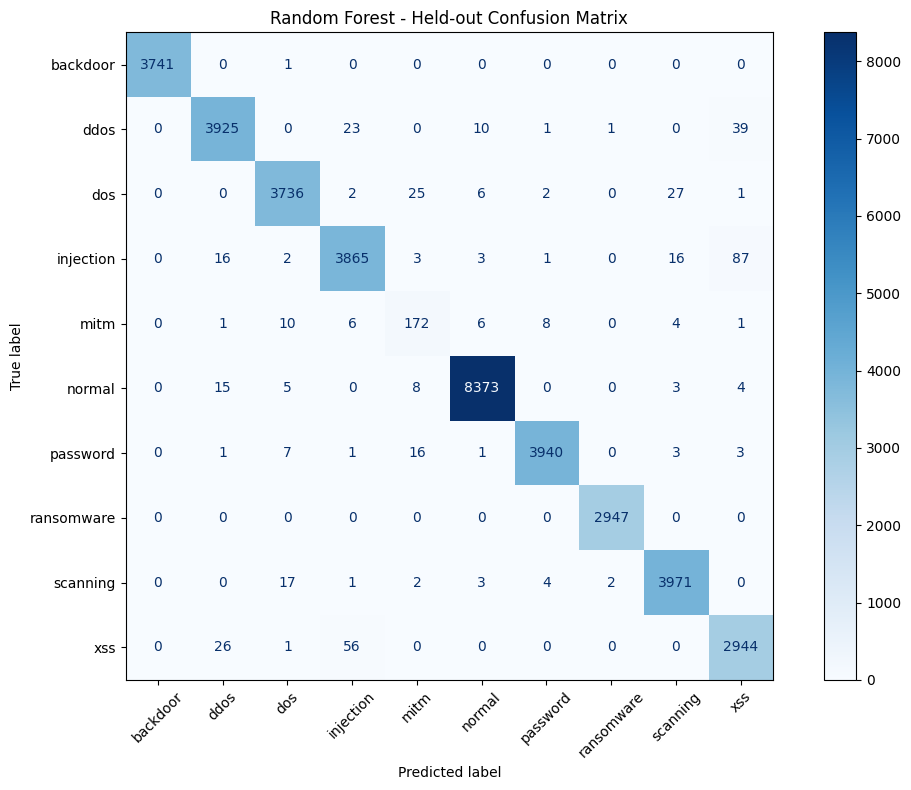


6. RANDOM FOREST FEATURE IMPORTANCE


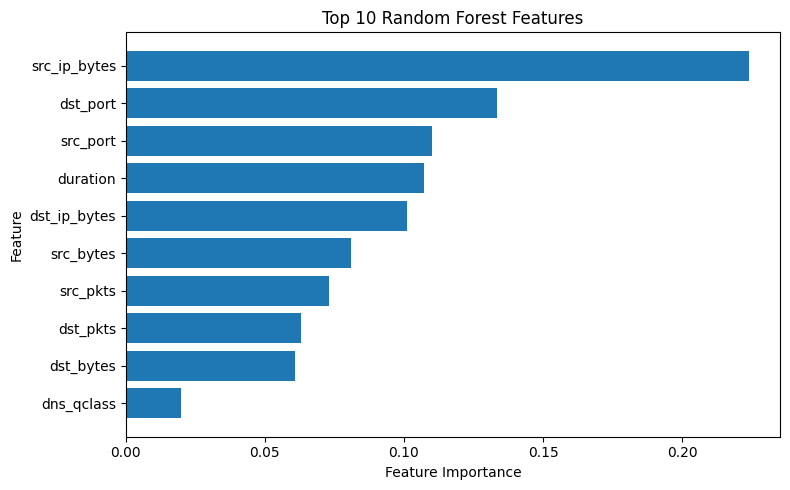


7. FINAL INTERPRETATION

Held-out Accuracy:
98.74%

External Agreement:
56.30%

Operational Confidence Threshold:
0.80

High-confidence Agreement:
93.07%

High-confidence Coverage:
41.57%

Malicious Events Entering Correlation:
1,253,175

Total Actor-centric Campaigns:
2,576

Candidate Multi-stage Campaigns:
4

Flow-to-Campaign Compression:
99.79%

IMPORTANT INTERPRETATION:

1. Candidate campaign does NOT mean confirmed causality.

2. Ground truth is used only AFTER autonomous
   detection and correlation.

3. ATT&CK mapping is contextual enrichment,
   not a complete threat-intelligence feed.

4. Response output is recommendation only.

5. Disruptive actions require analyst approval.


Saved Updated Files:
/content/drive/MyDrive/AutoSOC_Project/AutoSOC_UPDATED_Final_Report.csv
/content/drive/MyDrive/AutoSOC_Project/AutoSOC_UPDATED_GroundTruth_Validation.csv
/content/drive/MyDrive/AutoSOC_Project/AutoSOC_UPDATED_Final_Metrics.csv

CELL 5 COMPLETE ✅
UPDATED AUTOSOC PIPELINE FINISHED ✅


In [ ]:
# ============================================================
# AUTOSOC - UPDATED FINAL VERSION
# CELL 5
# GROUND-TRUTH VALIDATION + FINAL EVALUATION
# ============================================================

print("=" * 90)
print("CELL 5 - GROUND-TRUTH VALIDATION + FINAL EVALUATION")
print("=" * 90)

GROUND_TRUTH_FILES = [
    1,
    9,
    16,
    18
]

# ============================================================
# PART A
# CANDIDATE CAMPAIGN VALIDATION
# ============================================================

validation_candidates = campaigns[

    campaigns[
        "campaign_type"
    ]
    ==
    "Candidate Multi-stage"

].copy().reset_index(
    drop=True
)

print(
    "\nCandidate campaigns to validate:",
    len(
        validation_candidates
    )
)

# ------------------------------------------------------------
# COLUMN FINDER
# ------------------------------------------------------------

def find_column(
    columns,
    possible_names
):

    lower_map = {

        str(col)
        .lower()
        .strip():
            col

        for col
        in columns
    }

    for name in possible_names:

        key = (
            name
            .lower()
            .strip()
        )

        if key in lower_map:

            return lower_map[
                key
            ]

    return None


# ------------------------------------------------------------
# COLLAPSE CONSECUTIVE LABELS
# ------------------------------------------------------------

def collapse_sequence(
    items
):

    result = []

    previous = None

    for item in items:

        if pd.isna(
            item
        ):

            continue

        item = str(
            item
        ).strip()

        if item != previous:

            result.append(
                item
            )

        previous = item

    return result


# ------------------------------------------------------------
# SUBSEQUENCE CHECK
# ------------------------------------------------------------

def is_subsequence(
    predicted,
    actual
):

    if not predicted:

        return False

    position = 0

    for item in actual:

        if (

            position
            <
            len(
                predicted
            )

            and

            item
            ==
            predicted[
                position
            ]
        ):

            position += 1

    return (

        position
        ==
        len(
            predicted
        )
    )


campaign_validation = pd.DataFrame()

# ============================================================
# LOAD RELEVANT GROUND TRUTH
# ============================================================

if len(
    validation_candidates
) > 0:

    # --------------------------------------------------------
    # SOURCE-SPECIFIC BROAD TIME RANGES
    # --------------------------------------------------------

    source_ranges = (

        validation_candidates

        .groupby(
            "src_ip"
        )

        .agg(

            min_start=(
                "start_time",
                "min"
            ),

            max_end=(
                "end_time",
                "max"
            )
        )

        .reset_index()
    )

    gt_parts = []

    # --------------------------------------------------------
    # READ GT FILES
    # --------------------------------------------------------

    for file_id in GROUND_TRUTH_FILES:

        gt_path = os.path.join(

            BASE_PATH,

            f"GroundTruth_Network_{file_id}.csv"
        )

        print(
            f"\nReading GroundTruth_Network_{file_id}.csv"
        )

        header = pd.read_csv(
            gt_path,
            nrows=0
        )

        columns = (
            header
            .columns
            .tolist()
        )

        timestamp_column = find_column(

            columns,

            [
                "ts",
                "timestamp",
                "time"
            ]
        )

        source_column = find_column(

            columns,

            [
                "src_ip",
                "source_ip",
                "srcip"
            ]
        )

        destination_column = find_column(

            columns,

            [
                "dst_ip",
                "destination_ip",
                "dstip"
            ]
        )

        type_column = find_column(

            columns,

            [
                "type",
                "attack_type",
                "label"
            ]
        )

        if (

            timestamp_column is None

            or

            source_column is None

            or

            type_column is None
        ):

            raise ValueError(

                f"GroundTruth_Network_{file_id}.csv "
                f"does not contain required columns."
            )

        use_columns = [

            timestamp_column,

            source_column,

            type_column
        ]

        if destination_column is not None:

            use_columns.append(
                destination_column
            )

        chunks = pd.read_csv(

            gt_path,

            usecols=use_columns,

            chunksize=200000,

            low_memory=False
        )

        for chunk in chunks:

            temp = pd.DataFrame({

                "ts":

                    pd.to_numeric(

                        chunk[
                            timestamp_column
                        ],

                        errors="coerce"
                    ),

                "src_ip":

                    chunk[
                        source_column
                    ]

                    .astype(str)

                    .str.strip(),

                "actual_type":

                    chunk[
                        type_column
                    ]

                    .astype(str)

                    .str.lower()

                    .str.strip()
            })

            if destination_column is not None:

                temp[
                    "dst_ip"
                ] = (

                    chunk[
                        destination_column
                    ]

                    .astype(str)

                    .str.strip()
                )

            else:

                temp[
                    "dst_ip"
                ] = None

            temp = temp.dropna(

                subset=[
                    "ts",
                    "src_ip",
                    "actual_type"
                ]
            )

            keep_mask = pd.Series(

                False,

                index=temp.index
            )

            for _, source_range in (
                source_ranges
                .iterrows()
            ):

                keep_mask |= (

                    (
                        temp[
                            "src_ip"
                        ]
                        ==
                        str(
                            source_range[
                                "src_ip"
                            ]
                        )
                    )

                    &

                    (
                        temp[
                            "ts"
                        ]
                        >=
                        float(
                            source_range[
                                "min_start"
                            ]
                        )
                    )

                    &

                    (
                        temp[
                            "ts"
                        ]
                        <=
                        float(
                            source_range[
                                "max_end"
                            ]
                        )
                    )
                )

            selected = temp[
                keep_mask
            ].copy()

            if len(
                selected
            ) > 0:

                gt_parts.append(
                    selected
                )

    # --------------------------------------------------------
    # COMBINE GT
    # --------------------------------------------------------

    if gt_parts:

        ground_truth = pd.concat(

            gt_parts,

            ignore_index=True
        )

    else:

        ground_truth = pd.DataFrame(

            columns=[
                "ts",
                "src_ip",
                "dst_ip",
                "actual_type"
            ]
        )

    del gt_parts

    gc.collect()

    # ========================================================
    # VALIDATE EACH CANDIDATE
    # ========================================================

    validation_rows = []

    for _, campaign in (
        validation_candidates
        .iterrows()
    ):

        source_ip = str(
            campaign[
                "src_ip"
            ]
        )

        start_time = float(
            campaign[
                "start_time"
            ]
        )

        end_time = float(
            campaign[
                "end_time"
            ]
        )

        predicted_sequence = split_sequence(

            campaign[
                "attack_sequence"
            ]
        )

        # ----------------------------------------------------
        # SAME SOURCE + SAME TIME WINDOW
        # ----------------------------------------------------

        gt = ground_truth[

            (
                ground_truth[
                    "src_ip"
                ]
                ==
                source_ip
            )

            &

            (
                ground_truth[
                    "ts"
                ]
                >=
                start_time
            )

            &

            (
                ground_truth[
                    "ts"
                ]
                <=
                end_time
            )

        ].copy()

        gt = gt.sort_values(
            "ts"
        )

        # Remove normal GT
        gt_attack = gt[

            gt[
                "actual_type"
            ]
            !=
            "normal"

        ].copy()

        actual_sequence = collapse_sequence(

            gt_attack[
                "actual_type"
            ].tolist()
        )

        # ----------------------------------------------------
        # SET METRICS
        # ----------------------------------------------------

        predicted_set = set(
            predicted_sequence
        )

        actual_set = set(
            actual_sequence
        )

        overlap = (
            predicted_set
            &
            actual_set
        )

        union = (
            predicted_set
            |
            actual_set
        )

        predicted_support = (

            len(
                overlap
            )

            /
            len(
                predicted_set
            )

            if predicted_set

            else 0
        )

        ground_truth_coverage = (

            len(
                overlap
            )

            /
            len(
                actual_set
            )

            if actual_set

            else 0
        )

        jaccard = (

            len(
                overlap
            )

            /
            len(
                union
            )

            if union

            else 0
        )

        ordered_support = is_subsequence(

            predicted_sequence,

            actual_sequence
        )

        exact_match = (

            predicted_sequence
            ==
            actual_sequence
        )

        # ----------------------------------------------------
        # VALIDATION STATUS
        # ----------------------------------------------------

        if not actual_sequence:

            validation_status = (
                "No Ground-Truth Attack Support"
            )

        elif exact_match:

            validation_status = (
                "Exact Ground-Truth Sequence Support"
            )

        elif (

            ordered_support

            and

            predicted_support
            ==
            1.0
        ):

            validation_status = (
                "Ordered Ground-Truth Support"
            )

        elif len(
            overlap
        ) > 0:

            validation_status = (
                "Partial Ground-Truth Support"
            )

        else:

            validation_status = (
                "No Predicted-Label Support"
            )

        validation_rows.append({

            "src_ip":

                source_ip,

            "campaign_id":

                campaign[
                    "campaign_id"
                ],

            "predicted_attack_sequence":

                campaign[
                    "attack_sequence"
                ],

            "ground_truth_attack_sequence":

                (
                    " → ".join(
                        actual_sequence
                    )

                    if actual_sequence

                    else
                    "None"
                ),

            "ground_truth_attack_events":

                len(
                    gt_attack
                ),

            "predicted_label_support":

                round(
                    predicted_support,
                    4
                ),

            "ground_truth_label_coverage":

                round(
                    ground_truth_coverage,
                    4
                ),

            "label_jaccard":

                round(
                    jaccard,
                    4
                ),

            "ordered_sequence_support":

                ordered_support,

            "exact_sequence_match":

                exact_match,

            "validation_status":

                validation_status,

            "risk_score":

                campaign[
                    "risk_score"
                ],

            "risk_level":

                campaign[
                    "risk_level"
                ]
        })

    campaign_validation = pd.DataFrame(
        validation_rows
    )

else:

    print(
        "No candidate multi-stage campaign "
        "was produced."
    )


# ============================================================
# PART B
# STANDARD ML EVALUATION
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

macro_precision = precision_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)

macro_recall = recall_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)

macro_f1 = f1_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)

weighted_precision = precision_score(

    y_test,
    y_pred,

    average="weighted",

    zero_division=0
)

weighted_recall = recall_score(

    y_test,
    y_pred,

    average="weighted",

    zero_division=0
)

weighted_f1 = f1_score(

    y_test,
    y_pred,

    average="weighted",

    zero_division=0
)

model_summary = pd.DataFrame([{

    "Accuracy":

        f"{accuracy * 100:.2f}%",

    "Macro Precision":

        f"{macro_precision:.3f}",

    "Macro Recall":

        f"{macro_recall:.3f}",

    "Macro F1":

        f"{macro_f1:.3f}",

    "Weighted Precision":

        f"{weighted_precision:.3f}",

    "Weighted Recall":

        f"{weighted_recall:.3f}",

    "Weighted F1":

        f"{weighted_f1:.3f}"
}])

print(
    "\n1. MODEL PERFORMANCE"
)

display(
    model_summary
)


# ============================================================
# PART C
# EXTERNAL / CONFIDENCE EVALUATION
# ============================================================

print(
    "\n2. EXTERNAL + CONFIDENCE EVALUATION"
)

print(
    "Overall external agreement:",
    f"{external_accuracy * 100:.2f}%"
)

display(
    threshold_summary
)

display(
    external_report
)


# ============================================================
# PART D
# CAMPAIGN RESULTS
# ============================================================

campaign_summary = pd.DataFrame([{

    "Malicious Events":

        f"{len(events):,}",

    "Total Campaigns":

        f"{len(campaigns):,}",

    "Candidate Multi-stage":

        int(

            (
                campaigns[
                    "campaign_type"
                ]
                ==
                "Candidate Multi-stage"

            ).sum()
        ),

    "Non-progressive":

        int(

            (
                campaigns[
                    "campaign_type"
                ]
                ==
                "Correlated Multi-alert "
                "(Non-progressive)"

            ).sum()
        ),

    "Single-stage":

        int(

            (
                campaigns[
                    "campaign_type"
                ]
                ==
                "Single-stage"

            ).sum()
        ),

    "Flow-to-Campaign Compression":

        f"{alert_reduction:.2f}%"
}])

print(
    "\n3. CAMPAIGN RESULTS"
)

display(
    campaign_summary
)


# ============================================================
# PART E
# VALIDATION SUMMARY
# ============================================================

if len(
    campaign_validation
) > 0:

    avg_label_support = (

        campaign_validation[
            "predicted_label_support"
        ].mean()

        *
        100
    )

    avg_gt_coverage = (

        campaign_validation[
            "ground_truth_label_coverage"
        ].mean()

        *
        100
    )

    avg_jaccard = (

        campaign_validation[
            "label_jaccard"
        ].mean()

        *
        100
    )

    ordered_supported = int(

        campaign_validation[
            "ordered_sequence_support"
        ].sum()
    )

    exact_matches = int(

        campaign_validation[
            "exact_sequence_match"
        ].sum()
    )

    validation_summary = pd.DataFrame([{

        "Candidates Validated":

            len(
                campaign_validation
            ),

        "Avg Label Support":

            f"{avg_label_support:.2f}%",

        "Avg GT Coverage":

            f"{avg_gt_coverage:.2f}%",

        "Avg Jaccard":

            f"{avg_jaccard:.2f}%",

        "Ordered Support":

            ordered_supported,

        "Exact Match":

            exact_matches
    }])

    print(
        "\n4. GROUND-TRUTH VALIDATION"
    )

    display(
        validation_summary
    )

    print(
        "\nDetailed Candidate Validation:"
    )

    display(
        campaign_validation
    )

else:

    avg_label_support = 0
    avg_gt_coverage = 0
    avg_jaccard = 0
    ordered_supported = 0
    exact_matches = 0

    print(
        "\n4. GROUND-TRUTH VALIDATION"
    )

    print(
        "No candidate campaign was "
        "available for validation."
    )


# ============================================================
# PART F
# CONFUSION MATRIX
# ============================================================

print(
    "\n5. HELD-OUT CONFUSION MATRIX"
)

fig, ax = plt.subplots(
    figsize=(11, 8)
)

ConfusionMatrixDisplay.from_predictions(

    y_test,

    y_pred,

    labels=
        threat_model.classes_,

    xticks_rotation=45,

    cmap="Blues",

    values_format="d",

    ax=ax
)

ax.set_title(
    "Random Forest - Held-out Confusion Matrix"
)

plt.tight_layout()

plt.show()


# ============================================================
# PART G
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

print(
    "\n6. RANDOM FOREST FEATURE IMPORTANCE"
)

top_features = (

    feature_importance

    .head(10)

    .sort_values(
        "Importance",
        ascending=True
    )
)

plt.figure(
    figsize=(8, 5)
)

plt.barh(

    top_features[
        "Feature"
    ],

    top_features[
        "Importance"
    ]
)

plt.xlabel(
    "Feature Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top 10 Random Forest Features"
)

plt.tight_layout()

plt.show()


# ============================================================
# PART H
# FINAL INTERPRETATION
# ============================================================

print(
    "\n7. FINAL INTERPRETATION"
)

final_candidate_count = int(

    (
        campaigns[
            "campaign_type"
        ]
        ==
        "Candidate Multi-stage"

    ).sum()
)

print(
    f"""
Held-out Accuracy:
{accuracy * 100:.2f}%

External Agreement:
{external_accuracy * 100:.2f}%

Operational Confidence Threshold:
{OPERATIONAL_THRESHOLD:.2f}

High-confidence Agreement:
{high_conf_accuracy * 100:.2f}%

High-confidence Coverage:
{high_conf_coverage * 100:.2f}%

Malicious Events Entering Correlation:
{len(events):,}

Total Actor-centric Campaigns:
{len(campaigns):,}

Candidate Multi-stage Campaigns:
{final_candidate_count}

Flow-to-Campaign Compression:
{alert_reduction:.2f}%

IMPORTANT INTERPRETATION:

1. Candidate campaign does NOT mean confirmed causality.

2. Ground truth is used only AFTER autonomous
   detection and correlation.

3. ATT&CK mapping is contextual enrichment,
   not a complete threat-intelligence feed.

4. Response output is recommendation only.

5. Disruptive actions require analyst approval.
"""
)


# ============================================================
# PART I
# SAVE FINAL OUTPUTS
# ============================================================

VALIDATION_PATH = os.path.join(

    BASE_PATH,

    "AutoSOC_UPDATED_GroundTruth_Validation.csv"
)

METRICS_PATH = os.path.join(

    BASE_PATH,

    "AutoSOC_UPDATED_Final_Metrics.csv"
)

campaign_validation.to_csv(

    VALIDATION_PATH,

    index=False
)

final_metrics = pd.DataFrame({

    "Metric": [

        "Held-out Accuracy",

        "Macro Precision",

        "Macro Recall",

        "Macro F1",

        "Weighted Precision",

        "Weighted Recall",

        "Weighted F1",

        "External Agreement",

        "High-confidence Agreement",

        "High-confidence Coverage",

        "Malicious Events",

        "Total Campaigns",

        "Candidate Multi-stage Campaigns",

        "Flow-to-Campaign Compression",

        "Average Candidate Label Support",

        "Average Candidate GT Coverage",

        "Average Candidate Jaccard",

        "Ordered-supported Candidates",

        "Exact-matched Candidates"
    ],

    "Result": [

        f"{accuracy * 100:.2f}%",

        f"{macro_precision:.3f}",

        f"{macro_recall:.3f}",

        f"{macro_f1:.3f}",

        f"{weighted_precision:.3f}",

        f"{weighted_recall:.3f}",

        f"{weighted_f1:.3f}",

        f"{external_accuracy * 100:.2f}%",

        f"{high_conf_accuracy * 100:.2f}%",

        f"{high_conf_coverage * 100:.2f}%",

        f"{len(events):,}",

        f"{len(campaigns):,}",

        str(
            final_candidate_count
        ),

        f"{alert_reduction:.2f}%",

        f"{avg_label_support:.2f}%",

        f"{avg_gt_coverage:.2f}%",

        f"{avg_jaccard:.2f}%",

        str(
            ordered_supported
        ),

        str(
            exact_matches
        )
    ]
})

final_metrics.to_csv(

    METRICS_PATH,

    index=False
)

print(
    "\nSaved Updated Files:"
)

print(
    FINAL_REPORT_PATH
)

print(
    VALIDATION_PATH
)

print(
    METRICS_PATH
)

print(
    "\nCELL 5 COMPLETE ✅"
)

print(
    "UPDATED AUTOSOC PIPELINE FINISHED ✅"
)